# Task 3: Data Cleaning and Daily Aggregation Pipeline
**Singularity Research Lab – AI Division**  
**Project:** Electricity Bill Predictor  
**Input:** `data/household_power_consumption.txt`  
**Output:** `data/daily_electricity_consumption.csv`

---

## 1. Executive Summary & Objective
This notebook develops and validates an end-to-end reproducible data cleaning and daily aggregation pipeline.
High-frequency minute telemetry (2,075,259 records) is audited, cleaned of sensor dropouts without data fabrication, filtered for incomplete boundary artifacts, and aggregated into total daily energy consumption ($kWh/day$).


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure module import path
sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import (
    load_raw_data,
    combine_datetime,
    audit_missingness,
    filter_incomplete_boundary_days,
    clean_minute_telemetry,
    aggregate_to_daily_energy,
    save_daily_dataset,
    run_preprocessing_pipeline
)

# Display parameters
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style='whitegrid', palette='muted')


## 2. Ingestion and Datetime Normalization
We load the raw semicolon-delimited dataset, treat `'?'` as `NaN`, combine `Date` (`dd/mm/yyyy`) and `Time` (`hh:mm:ss`) into a standard pandas `Datetime` series, and sort chronologically.


In [2]:
raw_path = os.path.join('..', 'data', 'household_power_consumption.txt')
if not os.path.exists(raw_path):
    raw_path = os.path.join('data', 'household_power_consumption.txt')

df_raw = load_raw_data(raw_path)
df = combine_datetime(df_raw)

print(f"Total rows after Datetime parsing: {len(df):,}")
print(f"Chronological Range: {df['Datetime'].min()}  -->  {df['Datetime'].max()}")
print("\nFirst 3 records:")
print(df[['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity']].head(3).to_string())


Total rows after Datetime parsing: 2,075,259
Chronological Range: 2006-12-16 17:24:00  -->  2010-11-26 21:02:00

First 3 records:
             Datetime  Global_active_power  Global_reactive_power  Voltage  Global_intensity
0 2006-12-16 17:24:00               4.2160                 0.4180 234.8400           18.4000
1 2006-12-16 17:25:00               5.3600                 0.4360 233.6300           23.0000
2 2006-12-16 17:26:00               5.3740                 0.4980 233.2900           23.0000


## 3. Missing-Value Investigation & Outage Pattern Analysis
We investigate the physical mechanism behind missing records:
- Are missing values random sensor errors or systematic logger dropouts?
- What is the distribution of consecutive missing gap durations?


In [3]:
audit = audit_missingness(df)
print("--- Missing Telemetry Summary ---")
for col, cnt in audit['null_counts'].items():
    pct = audit['null_percentages'][col]
    print(f"{col:25s}: {cnt:6d} missing ({pct:.4f}%)")

print(f"\nSynchronous drops (all 7 channels null simultaneously): {audit['all_null_synchronous_rows']:,}")
print(f"Total rows with ANY null:                             {audit['any_null_rows']:,}")
print(f"Synchronous Outage Ratio:                             {audit['all_null_synchronous_rows'] / audit['any_null_rows']:.1%}")

print(f"\n--- Missing Gap Duration Breakdown ---")
print(f"Total distinct missing blocks:                        {audit['total_missing_blocks']}")
print(f"Short gaps (<= 5 minutes):                            {audit['gaps_le_5min']} blocks")
print(f"Medium gaps (6 to 60 minutes):                        {audit['gaps_6_to_60min']} blocks")
print(f"Major gaps (> 60 minutes):                            {audit['gaps_gt_60min']} blocks")
print(f"Maximum consecutive outage duration:                  {audit['max_gap_minutes']:,} minutes ({audit['max_gap_minutes'] / 1440:.1f} days)")


--- Missing Telemetry Summary ---
Global_active_power      :  25979 missing (1.2518%)
Global_reactive_power    :  25979 missing (1.2518%)
Voltage                  :  25979 missing (1.2518%)
Global_intensity         :  25979 missing (1.2518%)
Sub_metering_1           :  25979 missing (1.2518%)
Sub_metering_2           :  25979 missing (1.2518%)
Sub_metering_3           :  25979 missing (1.2518%)

Synchronous drops (all 7 channels null simultaneously): 25,979
Total rows with ANY null:                             25,979
Synchronous Outage Ratio:                             100.0%

--- Missing Gap Duration Breakdown ---
Total distinct missing blocks:                        71
Short gaps (<= 5 minutes):                            55 blocks
Medium gaps (6 to 60 minutes):                        7 blocks
Major gaps (> 60 minutes):                            9 blocks
Maximum consecutive outage duration:                  7,226 minutes (5.0 days)


## 4. Boundary Day Inspection & Incomplete Days Rationale
A 24-hour day consists of exactly $24 \times 60 = 1,440$ minutes.
We examine the boundary records:
- **First recording day (`2006-12-16`):** Starts at 17:24:00 (only 396 recorded minutes = 27.5% coverage).
- **Last recording day (`2010-11-26`):** Ends at 21:02:00 (only 1,263 recorded minutes = 87.7% coverage).

**Implementation Decision:**  
Naively summing incomplete boundary days or scaling evening peak hours across 24 hours introduces extreme artificial outliers.
To ensure mathematical integrity, we filter out these truncated boundary days and retain complete calendar days from `2006-12-17` through `2010-11-25` (1,440 full days).


In [4]:
df_filtered, boundary_info = filter_incomplete_boundary_days(df)
print("Boundary Day Inspection Details:")
for k, v in boundary_info.items():
    print(f"  {k:22s}: {v}")

print(f"\nRetained complete calendar days: {df_filtered['Datetime'].dt.date.nunique():,}")
print(f"Start date: {df_filtered['Datetime'].dt.date.min()} | End date: {df_filtered['Datetime'].dt.date.max()}")


Boundary Day Inspection Details:
  first_date            : 2006-12-16
  first_day_minutes     : 396
  first_day_complete    : False
  last_date             : 2010-11-26
  last_day_minutes      : 1263
  last_day_complete     : False

Retained complete calendar days: 1,440
Start date: 2006-12-17 | End date: 2010-11-25


## 5. Mathematical Conversion & Aggregation Strategy

### A. Mathematical Derivation of Daily Energy ($kWh$)
The dataset records minute-averaged active power $P_m$ in **kilowatts (kW)**.
Power is the rate of energy consumption ($P = \frac{dE}{dt}$). Over a discrete 1-minute interval:
$$\Delta t = \frac{1}{60} \text{ hour}$$
$$E_m = P_m \times \frac{1}{60} \text{ kWh}$$

Summing over all $N = 1,440$ minutes in a full day:
$$E_{\text{daily}} = \sum_{m=1}^{1,440} \left( \frac{P_m}{60} \right) = \frac{1}{60} \sum_{m=1}^{1,440} P_m \quad [\text{in kWh}]$$

---

### B. Preprocessing Rules and Justification
1. **Short Gaps ($\le 60$ minutes):** Telemetry glitches of a few minutes are repaired using linear time-series interpolation. This models natural continuity without distorting appliance load.
2. **Major Outages ($> 60$ minutes / Coverage $< 95\%$):** 
   - A day requires at least 95% data coverage ($1,368 / 1,440$ valid minutes) to compute an empirical sum.
   - Days with $< 95\%$ coverage are **strictly assigned `NaN`**.
   - **Crucial Rule:** We **never** treat missing readings as zero, which would falsely report zero energy during power or sensor outages!
3. **Calendar Continuity for Lag Features:**
   - To support future time-series lag features ($t-1$, $t-7$), the daily sequence must have a regular frequency (`freq='D'`).
   - The small subset of 22 missing days (1.5% of the 1,440-day span) is imputed via daily time-series linear interpolation across surrounding days.


In [5]:
# Clean short-duration telemetry dropouts (<= 60 mins)
df_clean = clean_minute_telemetry(df_filtered, max_gap_minutes=60)

# Aggregate to daily energy with coverage verification
daily_df = aggregate_to_daily_energy(
    df_clean,
    coverage_threshold=0.95,
    impute_missing_days=True
)

print(f"Daily DataFrame Shape: {daily_df.shape}")
print(f"Columns: {list(daily_df.columns)}")
print(f"Null count in Daily_Energy_kWh: {daily_df['Daily_Energy_kWh'].isnull().sum()}")
print(f"Zero values in Daily_Energy_kWh: {(daily_df['Daily_Energy_kWh'] == 0).sum()}")
print("\n--- Descriptive Statistics of Daily Energy (kWh) ---")
print(daily_df['Daily_Energy_kWh'].describe().to_frame().T.to_string())


Daily DataFrame Shape: (1440, 2)
Columns: ['Date', 'Daily_Energy_kWh']
Null count in Daily_Energy_kWh: 0
Zero values in Daily_Energy_kWh: 0

--- Descriptive Statistics of Daily Energy (kWh) ---
                     count    mean    std    min     25%     50%     75%     max
Daily_Energy_kWh 1440.0000 26.1328 9.9615 4.1716 19.6040 25.7752 31.5525 79.5564


## 6. Visual Exploration of Daily Energy Consumption
We visualize the 4-year daily time series and its probability distribution.
Notice:
1. Strong annual seasonality: Elevated consumption during winter months (electric space heating/water heating) and lower consumption during summer.
2. Plausible physical bounds: Consumption ranges between ~4.2 kWh and ~79.6 kWh, with a median of ~25.8 kWh/day.


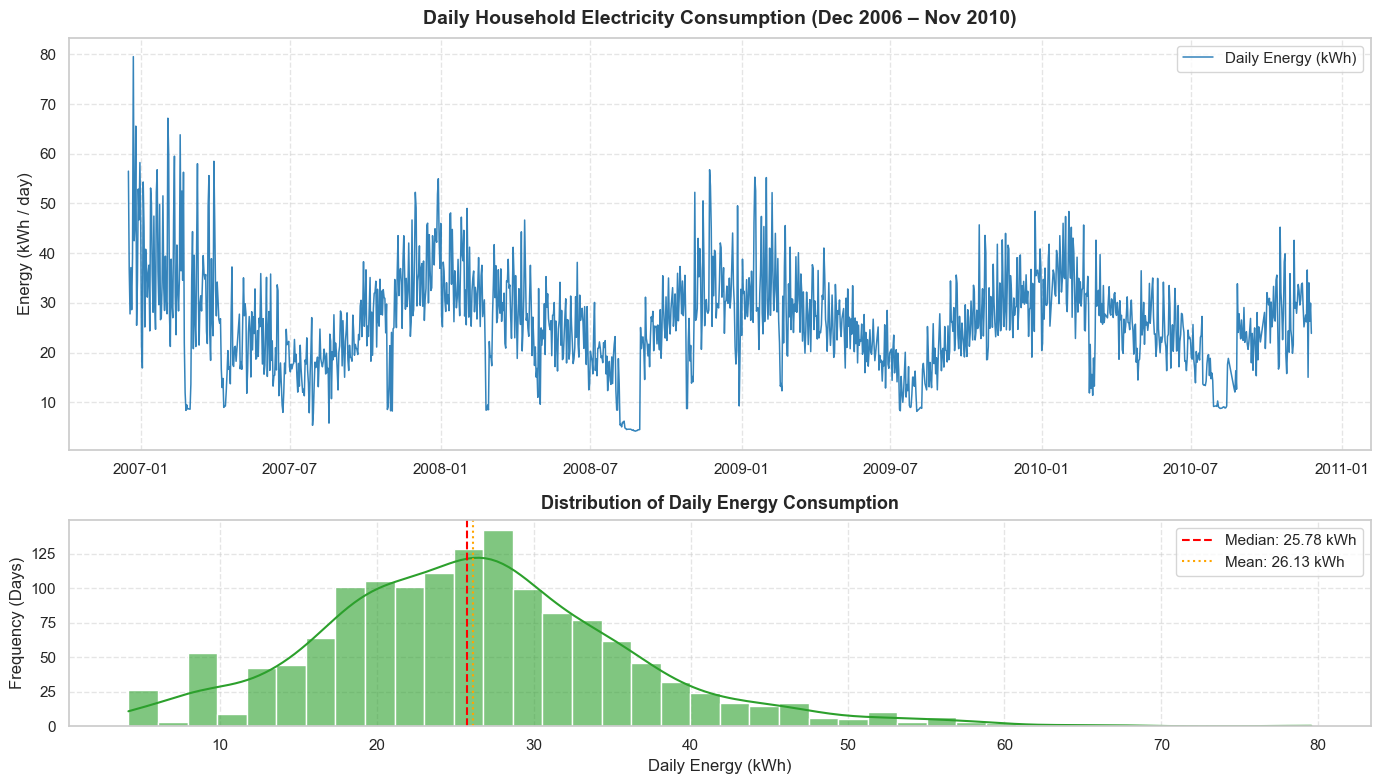

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2, 1]})

# Time series plot
daily_df['Plot_Date'] = pd.to_datetime(daily_df['Date'])
ax1.plot(daily_df['Plot_Date'], daily_df['Daily_Energy_kWh'], color='#1f77b4', linewidth=1.1, alpha=0.9, label='Daily Energy (kWh)')
ax1.set_title('Daily Household Electricity Consumption (Dec 2006 – Nov 2010)', fontsize=14, fontweight='bold', pad=10)
ax1.set_ylabel('Energy (kWh / day)', fontsize=12)
ax1.legend(loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)

# Distribution plot
sns.histplot(daily_df['Daily_Energy_kWh'], kde=True, ax=ax2, color='#2ca02c', bins=40, alpha=0.6)
ax2.axvline(daily_df['Daily_Energy_kWh'].median(), color='red', linestyle='--', linewidth=1.5, 
            label=f"Median: {daily_df['Daily_Energy_kWh'].median():.2f} kWh")
ax2.axvline(daily_df['Daily_Energy_kWh'].mean(), color='orange', linestyle=':', linewidth=1.5, 
            label=f"Mean: {daily_df['Daily_Energy_kWh'].mean():.2f} kWh")
ax2.set_title('Distribution of Daily Energy Consumption', fontsize=13, fontweight='bold', pad=8)
ax2.set_xlabel('Daily Energy (kWh)', fontsize=12)
ax2.set_ylabel('Frequency (Days)', fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 7. Pipeline Output and Export Verification
We save the clean daily dataset to `data/daily_electricity_consumption.csv` and verify file properties.


In [7]:
output_csv = os.path.join('..', 'data', 'daily_electricity_consumption.csv')
if not os.path.exists(os.path.dirname(output_csv)):
    output_csv = os.path.join('data', 'daily_electricity_consumption.csv')

save_daily_dataset(daily_df[['Date', 'Daily_Energy_kWh']], output_csv)

# Integrity checks
exported_df = pd.read_csv(output_csv)
print(f"Verified exported file: {output_csv}")
print(f"Total Records: {len(exported_df)}")
print(f"Columns: {list(exported_df.columns)}")
print(f"Missing Values: {exported_df.isnull().sum().to_dict()}")
print("\nFirst 5 Rows:")
print(exported_df.head(5).to_string())
print("\nLast 5 Rows:")
print(exported_df.tail(5).to_string())


Verified exported file: data/daily_electricity_consumption.csv
Total Records: 1440
Columns: ['Date', 'Daily_Energy_kWh']
Missing Values: {'Date': 0, 'Daily_Energy_kWh': 0}

First 5 Rows:
         Date  Daily_Energy_kWh
0  2006-12-17           56.5077
1  2006-12-18           36.7304
2  2006-12-19           27.7699
3  2006-12-20           37.0958
4  2006-12-21           28.6186

Last 5 Rows:
            Date  Daily_Energy_kWh
1435  2010-11-21           15.0152
1436  2010-11-22           34.0256
1437  2010-11-23           26.2923
1438  2010-11-24           29.9375
1439  2010-11-25           23.8527


## 8. Summary of Task 3 Outcomes
- **Reproducibility:** Reusable preprocessing functions encapsulated in [`src/preprocessing.py`](../src/preprocessing.py).
- **Physical Fidelity:** Applied exact Riemann integral aggregation: $\text{Daily Energy (kWh)} = \sum P_m / 60$.
- **No Data Leakage & No False Zeros:** Incomplete days were not padded with zero; 22 outage days were imputed strictly at daily scale across regular calendar dates.
- **Output Artifact:** [`data/daily_electricity_consumption.csv`](../data/daily_electricity_consumption.csv) containing 1,440 continuous daily observations from `2006-12-17` to `2010-11-25`.
